# 18 · Literature-weighted harm and priced false positives (secondary, post hoc)

**Status: secondary and post hoc.** No dated lock specified this analysis. It reads only frozen v2 prediction files, changes no locked result, and labels everything it writes as secondary. It covers the three retinal populations: EyePACS fresh set, DDR and BRSET. It uses the 33 EyePACS-trained models (11 architectures × 3 seeds) and the 55 architecture pairs × 9 seed combinations, exactly as in lock v3.

**Why.** The confirmatory results count missed eyes at matched referral volume, so they need no weights. The rejected v1 leaned on heuristic weights (500 / 200 / 15). This notebook asks two questions:
1. Does the matched-volume benefit hold when misses are weighted by literature-derived harm instead?
2. Once false positives carry a price in the same unit, and every arm is tuned to its own best volume, does a pair still beat its better member? Where does referring everything either model flags (the union) land?

**Harm per missed referable eye** (one-year screening delay; values and sources in the table below):

| Missed eye | Severe visual loss events per missed eye | Source |
|---|---|---|
| Grade 4 (PDR) | 0.0475 (range 0.02 to 0.075) | DRS: 2-year severe visual loss untreated vs treated, 26% vs 11% with high-risk characteristics, 7% vs 3% without; halved per year, midpoint central |
| Grade 3 (severe NPDR) | 0.15 × 0.5 × PDR rate + 0.002 | ETDRS Reports 9 and 12: about 15% reach high-risk PDR within a year, untreated for about half the interval; DRS Report 14 direct excess 3.2% vs 2.8% over 2 years |
| Grade 2 (moderate NPDR) | 0.04 × 0.5 × PDR rate (0.02 to 0.08 range) | Lee et al. 2017 (UK DR EMR Users Group Report 3): 4.0% progress to PDR within a year; modelled as for grade 3. Macular oedema is not labelled in these datasets and is left out, which understates grade 2 harm |

Each severe visual loss event costs 15 sight-years (range 10 to 20, an assumption). At 0.214 QALYs per blind year (Moshfeghi et al. 2020) that is 3.21 QALYs per event.

**Primary pricing: false referrals per prevented blind eye (K).** A false positive is priced as 1/K of one severe visual loss event. K is how many false referrals of grade 0 or 1 eyes a programme would accept to prevent one eye going blind. It is swept from 10 to 10,000. For each population the notebook reports the **break-even K**: the value above which a pair, with each arm tuned to its own best volume, beats its better member. No utility value is needed.

**Secondary, clinically framed: only-eye (worst-case) valuation.** The 0.214 is the QALY loss per legally blind *person*. Charging it to every single-eye event assumes the missed eye is the patient's only seeing eye. No credit is taken for the fellow eye, the same way a detachment repair assumes no help from the other eye. This makes the harm side an upper bound, and it is stated as one. Two consequences:
- **It favours referring more.** So a result where pairing or the union does *not* pay even under this valuation is robust.
- **Translation to K.** It maps onto the K axis: one visit at 0.001 to 0.004 QALY against 3.21 QALY per event gives K of about 800 to 3,200. That band is shaded on the primary figure, and section B2 repeats the analysis in QALYs.

**Price of a false positive** (a grade 0 or 1 eye referred) is λ QALYs, swept from 0.0001 to 0.03. The shaded band (0.001 to 0.004 QALY) is one specialist visit at $150 to $400 with a willingness to pay of $100,000 to $150,000 per QALY. **These cost figures are assumptions still to be sourced** before the band is cited.

**Analyses.**
- **A. Matched volume, reweighted.** At each population's locked referral fraction (EyePACS 25%; DDR and BRSET 1.31 × referable prevalence), the pair's harm minus the better member's harm, averaged over all pairs. Weightings: npj heuristic, literature (central, low, high), severe count, PDR count.
- **B. Free volume, priced (primary in K).** Each arm (member a alone, member b alone, the pair) takes its own cost-minimising referral volume at each K. Reported: tuned pair minus tuned better member, in event-equivalents per 10,000 eyes, and the break-even K with a bootstrap interval. Literature low and high harm are shown as sensitivity.
- **B2. The same, in QALYs under the only-eye valuation (secondary).**
- **C. The npj 25-cell weight grid, fully tuned, on v2 data.** It replaces the earlier v1 invariance figure, which predates the rebuild.
- **D. Union at each model's own threshold.** Harm avoided, extra false positives and net QALYs per 10,000 eyes against the better member, at the anchored λ.

**Uncertainty.** 1,000 bootstrap resamples (seed 20261028) of patients (EyePACS, BRSET) or filename groups (DDR). Each model's rank transform is fixed at the full sample, so the resamples are conditional on the rankings, as in the DDR v5.1 analysis.

**Runtime:** CPU, high-RAM, about 10 to 20 minutes. BRSET stays in your Drive and runtime. Only aggregate numbers are written or printed; no image or patient identifier leaves the notebook.

In [1]:
# --- setup ---
from google.colab import drive
drive.mount("/content/drive")
import os, re, json, hashlib, itertools, datetime, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import rankdata
BASE = "/content/drive/MyDrive/stochastic_orthogonality/data/dr_ensemble_v2"
PREDS, SPLITS, RESULTS, FIGS = (f"{BASE}/{d}" for d in ("03_predictions", "01_splits", "04_results", "05_figures"))
BRSET_LABELS = "/content/drive/MyDrive/stochastic_orthogonality/data/brset/label_brset.csv"
OUT_JSON = f"{RESULTS}/literature_weighted_secondary_v2.json"
assert not os.path.exists(OUT_JSON), "this secondary analysis has already been written; rename the old output deliberately to rerun"
def sha256_file(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""): h.update(b)
    return h.hexdigest()
ARCHS = ["densenet121_binary", "densenet121_5class", "efficientnet_b3_binary", "efficientnet_b3_5class", "resnet50_binary", "resnet50_5class",
         "vit_base_binary", "vit_base_5class", "retfound_binary", "retfound_5class", "retfound_adversarial"]
SEEDS = [0, 1, 2]; PAIRS = list(itertools.combinations(ARCHS, 2))
def tag(k): return "" if k == 0 else f"_seed{k}"
MODELS = [(a, k) for a in ARCHS for k in SEEDS]
B, SEED = 1000, 20261028
VOLS = np.round(np.arange(0.01, 0.701, 0.01), 2)

# harm model (severe visual loss events per missed eye, one-year delay)
PDR = {"low": 0.02, "central": 0.0475, "high": 0.075}
P_HR_G3, DIRECT_G3 = 0.15, 0.002
P_PDR_G2 = {"low": 0.02, "central": 0.04, "high": 0.08}
SY = {"low": 10, "central": 15, "high": 20}; QALY_PER_BLIND_YEAR = 0.214
def svl(grade, sc):
    r = PDR[sc]
    return np.select([grade == 4, grade == 3, grade == 2], [r, P_HR_G3 * 0.5 * r + DIRECT_G3, P_PDR_G2[sc] * 0.5 * r], 0.0)
KS = np.round(np.geomspace(10, 10000, 31), 1)          # false referrals one prevented severe visual loss event is worth
LAMBDAS = np.round(np.geomspace(1e-4, 3e-2, 25), 6); BAND = (0.001, 0.004); LAM_ANCHOR = 0.0025
NPJ_GRID = {"miss": [[500, 200, 15], [250, 100, 10], [1000, 400, 20], [100, 50, 10], [50, 25, 5]], "wfp": [1, 5, 20, 50, 100]}
for sc in ("low", "central", "high"):
    print(f"{sc:>7}: per missed eye, severe visual loss events  g4 {svl(np.array(4), sc):.4f}  g3 {svl(np.array(3), sc):.4f}  g2 {svl(np.array(2), sc):.5f}"
          f"  | QALY per event {SY[sc] * QALY_PER_BLIND_YEAR:.2f}")

Mounted at /content/drive
    low: per missed eye, severe visual loss events  g4 0.0200  g3 0.0035  g2 0.00020  | QALY per event 2.14
central: per missed eye, severe visual loss events  g4 0.0475  g3 0.0056  g2 0.00095  | QALY per event 3.21
   high: per missed eye, severe visual loss events  g4 0.0750  g3 0.0076  g2 0.00300  | QALY per event 4.28


## 1. Load the three populations (frozen predictions only)

In [2]:
def pick(cols, pats, what):
    m = [c for c in cols if any(re.fullmatch(p, c, flags=re.I) for p in pats)]
    assert len(m) == 1, f"cannot identify the {what} column; columns are {list(cols)}"
    return m[0]
F_OVERRIDE = {}   # e.g. {"ddr": 0.56} if the printed f differs from the locked value
def norm(x): return pd.Series(x, dtype=str).str.replace(r"\.(jpe?g|png|tiff?)$", "", regex=True, flags=re.I).to_numpy()
HASHES = {}
def load_preds(fmt, key="image_id"):
    P = {}; ref = None
    for a, k in MODELS:
        fn = f"{PREDS}/{fmt.format(arch=a, tag=tag(k))}"; HASHES[os.path.basename(fn)] = sha256_file(fn)
        d = pd.read_csv(fn, dtype={key: str})
        if ref is None: ref = d
        else: assert (d[key].values == ref[key].values).all(), f"row order differs in {os.path.basename(fn)}"
        P[(a, k)] = d["predicted_probability"].to_numpy(np.float64)
    return ref, P
POP = {}
# EyePACS fresh set (labels and patients travel with the prediction files)
ref, P = load_preds("eyepacs_predictions_fresh_{arch}{tag}_v2.csv")
POP["eyepacs"] = {"grade": ref.true_grade.to_numpy(int), "group": ref.patient_id.astype(str).to_numpy(), "P": P, "f": 0.25}
# DDR (labels and filename groups from the intraset split written before inference)
ref, P = load_preds("ddr_predictions_{arch}{tag}_v2.csv")
sp = pd.read_csv(f"{SPLITS}/ddr_split_intraset_v2.csv", dtype={"image_id": str})
gcol, grpcol = pick(sp.columns, ["grade", "true_grade", "dr_grade", "level"], "DDR grade"), pick(sp.columns, ["group", "filename_group", "group_id"], "DDR group")
sp["_k"] = norm(sp["image_id"]); sp = sp.set_index("_k").loc[norm(ref.image_id)]
half = [c for c in sp.columns if re.fullmatch("half|split|subset", c, flags=re.I)]
g = sp[gcol].to_numpy(int); keep = g <= 4
if half:
    isA = sp[half[0]].astype(str).str.strip().str.upper().isin(["A", "HALF_A", "HALFA", "0"]).to_numpy()
    print("DDR half column:", half[0], "| values:", sorted(sp[half[0]].astype(str).unique())[:6], "| treated as half A:", int((isA & keep).sum()), "eyes")
else:
    isA = np.ones(len(g), bool); print("WARNING: no DDR half column found; f uses the whole DDR prevalence")
prevA = float((g[keep & isA] >= 2).mean())
POP["ddr"] = {"grade": g[keep], "group": sp[grpcol].astype(str).to_numpy()[keep], "P": {m: v[keep] for m, v in P.items()}, "f": round(1.31 * prevA, 4)}
# BRSET (labels read from the BRSET label file; only aggregates leave this runtime)
ref, P = load_preds("brset_predictions_eyepacs_{arch}{tag}_v2.csv")
lb = pd.read_csv(BRSET_LABELS, dtype=str)
icol, pcol, idcol = pick(lb.columns, [r".*icdr.*"], "BRSET ICDR grade"), pick(lb.columns, ["patient_id", "patient"], "BRSET patient"), pick(lb.columns, ["image_id", "image"], "BRSET image id")
lb["_k"] = norm(lb[idcol]); lb = lb.set_index("_k").loc[norm(ref.image_id)]
g = pd.to_numeric(lb[icol], errors="coerce").to_numpy(); keep = np.isin(g, [0, 1, 2, 3, 4])
POP["brset"] = {"grade": g[keep].astype(int), "group": lb[pcol].astype(str).to_numpy()[keep], "P": {m: v[keep] for m, v in P.items()}}
POP["brset"]["f"] = round(1.31 * float((POP["brset"]["grade"] >= 2).mean()), 4)
for name, v in F_OVERRIDE.items(): POP[name]["f"] = v
for name, d in POP.items():
    gr = d["grade"]
    print(f"{name:>8}: {len(gr):,} eyes | {len(set(d['group'])):,} groups | referable {np.mean(gr >= 2):.3f} | grade 3 {int((gr == 3).sum())} | grade 4 {int((gr == 4).sum())} | f = {d['f']}")
print("expected f from the manuscript: DDR about 0.56 (from half A), BRSET about 0.075")

DDR half column: half | values: ['A', 'B'] | treated as half A: 6205 eyes
 eyepacs: 15,794 eyes | 7,897 groups | referable 0.195 | grade 3 384 | grade 4 328 | f = 0.25
     ddr: 12,422 eyes | 332 groups | referable 0.453 | grade 3 236 | grade 4 913 | f = 0.555
   brset: 16,266 eyes | 8,524 groups | referable 0.057 | grade 3 78 | grade 4 396 | f = 0.0745
expected f from the manuscript: DDR about 0.56 (from half A), BRSET about 0.075


## 2. Core computation
Every single model and every pair is ranked once on the full sample. Each bootstrap resample is a vector of patient (or group) weights, so a resample changes cumulative sums along a fixed order and never re-sorts. The pair score is the higher of the two within-population ranks, with the lower one as a tie-break.

In [3]:
def setup(d):
    gr = d["grade"]; n = len(gr)
    codes = pd.factorize(d["group"])[0]; G = codes.max() + 1
    rng = np.random.default_rng(SEED)
    W = np.empty((B + 1, n), np.float32); W[0] = 1.0
    for b in range(1, B + 1): W[b] = np.bincount(rng.integers(0, G, G), minlength=G)[codes]
    contrib = {"npj": np.select([gr == 4, gr == 3, gr == 2], [500.0, 200.0, 15.0], 0.0),
               "severe_count": (gr >= 3).astype(float), "pdr_count": (gr == 4).astype(float), "fp": (gr <= 1).astype(float)}
    for sc in ("central", "low", "high"): contrib[f"lit_{sc}"] = svl(gr, sc)
    for w4, w3, w2 in NPJ_GRID["miss"]: contrib[f"grid_{w4}_{w3}_{w2}"] = np.select([gr == 4, gr == 3, gr == 2], [w4, w3, w2], 0.0)
    R = {m: rankdata(p) / n for m, p in d["P"].items()}
    return {"n": n, "W": W, "Wtot": W.sum(1, dtype=np.float64), "contrib": contrib, "R": R}
KEYS_MISS = ["npj", "severe_count", "pdr_count", "lit_central", "lit_low", "lit_high"] + [f"grid_{a}_{b}_{c}" for a, b, c in NPJ_GRID["miss"]]
def curves(S, score, vols):
    # for each resample and volume: weighted total of each contribution among eyes NOT referred (misses), and FP among eyes referred
    o = np.argsort(-score, kind="stable"); Wo = S["W"][:, o]; cw = np.cumsum(Wo, 1, dtype=np.float64)
    pos = np.empty((B + 1, len(vols)), np.int64)
    for b in range(B + 1): pos[b] = np.searchsorted(cw[b], vols * S["Wtot"][b], side="right")
    out = {}
    for k, c in S["contrib"].items():
        cc = np.cumsum(Wo * c[o].astype(np.float32), 1, dtype=np.float64); cc = np.concatenate([np.zeros((B + 1, 1)), cc], 1)
        got = np.take_along_axis(cc, pos, 1); tot = cc[:, -1:]
        out[k] = got if k == "fp" else tot - got                  # fp: referred false positives; others: missed
    return out
def per10k(x, S): return x / S["Wtot"][:, None] * 1e4 if x.ndim == 2 else x / S["Wtot"] * 1e4
def qaly_cost(cv, S, lam, sc="central"):
    return per10k(cv[f"lit_{sc}"] * SY[sc] * QALY_PER_BLIND_YEAR + lam * cv["fp"], S)       # QALYs per 10,000 eyes
print("ready")

ready


## 3. Run: singles, then every pair
For each population this computes:
- matched-volume harm at f;
- the tuned (cheapest-volume) QALY cost across λ;
- the tuned npj index across the 25-cell grid;
- the union at each model's own threshold.

Pair results are averaged over the 55 pairs × 9 seed combinations within each resample.

In [4]:
RES = {}
for name, d in POP.items():
    t0 = time.time(); S = setup(d); f = d["f"]; vols = np.unique(np.r_[VOLS, f]); iF = int(np.where(vols == f)[0][0])
    SING = {m: curves(S, S["R"][m], vols) for m in MODELS}
    print(f"{name}: singles done ({time.time() - t0:.0f}s)")
    def tuned_qaly(cv): return np.stack([qaly_cost(cv, S, lam).min(1) for lam in LAMBDAS], 1)                    # (B+1, n_lambda)
    def tuned_grid(cv): return np.stack([per10k(cv[f"grid_{a}_{b}_{c}"] + wfp * cv["fp"], S).min(1) for a, b, c in NPJ_GRID["miss"] for wfp in NPJ_GRID["wfp"]], 1)
    def tuned_k(cv): return {sc: np.stack([per10k(cv[f"lit_{sc}"] + cv["fp"] / K, S).min(1) for K in KS], 1) for sc in ("central", "low", "high")}
    TK = {m: tuned_k(SING[m]) for m in MODELS}
    TQ = {m: tuned_qaly(SING[m]) for m in MODELS}; TG = {m: tuned_grid(SING[m]) for m in MODELS}
    # each model's own top-f set on the full sample, for the union analysis
    own = {m: S["R"][m] >= np.quantile(S["R"][m], 1 - f) for m in MODELS}
    acc = {"matched": {k: [] for k in KEYS_MISS}, "tuned_k": {sc: [] for sc in ("central", "low", "high")}, "tuned_qaly": [], "tuned_grid": [], "union_harm_qaly": [], "union_fp": [], "union_severe": []}
    pair_point = []
    for a, bm in PAIRS:
        pp = []
        for i in SEEDS:
            for j in SEEDS:
                ma, mb = (a, i), (bm, j); ra, rb = S["R"][ma], S["R"][mb]
                cvp = curves(S, np.maximum(ra, rb) + 1e-9 * np.minimum(ra, rb), vols)
                for k in KEYS_MISS:
                    single = np.minimum(SING[ma][k][:, iF], SING[mb][k][:, iF]); acc["matched"][k].append(per10k(single - cvp[k][:, iF], S))
                tkp = tuned_k(cvp)
                for sc in tkp: acc["tuned_k"][sc].append(np.minimum(TK[ma][sc], TK[mb][sc]) - tkp[sc])
                acc["tuned_qaly"].append(np.minimum(TQ[ma], TQ[mb]) - tuned_qaly(cvp))
                acc["tuned_grid"].append(np.minimum(TG[ma], TG[mb]) - tuned_grid(cvp))
                # union at each model's own threshold vs the better member (fewer severe misses at f, per resample)
                u = own[ma] | own[mb]; W = S["W"]; c = S["contrib"]
                h = lambda ref: (W * (~ref * c["lit_central"])).sum(1) * SY["central"] * QALY_PER_BLIND_YEAR
                sv = lambda ref: (W * (~ref * c["severe_count"])).sum(1); fp = lambda ref: (W * (ref * c["fp"])).sum(1)
                better_a = sv(own[ma]) <= sv(own[mb]); base_h = np.where(better_a, h(own[ma]), h(own[mb])); base_fp = np.where(better_a, fp(own[ma]), fp(own[mb]))
                base_sv = np.where(better_a, sv(own[ma]), sv(own[mb]))
                acc["union_harm_qaly"].append(per10k(base_h - h(u), S)); acc["union_fp"].append(per10k(fp(u) - base_fp, S)); acc["union_severe"].append(per10k(base_sv - sv(u), S))
                pp.append(acc["matched"]["lit_central"][-1][0])
        pair_point.append(np.mean(pp))
    mean_ = lambda L: np.mean(np.stack(L), 0)                       # mean over the 495 pair x seed combinations, per resample
    RES[name] = {"f": f, "n": S["n"], "groups": int(len(set(d["group"]))),
                 "matched": {k: mean_(v) for k, v in acc["matched"].items()}, "tuned_k": {sc: mean_(v) for sc, v in acc["tuned_k"].items()}, "tuned_qaly": mean_(acc["tuned_qaly"]), "tuned_grid": mean_(acc["tuned_grid"]),
                 "union_harm_qaly": mean_(acc["union_harm_qaly"]), "union_fp": mean_(acc["union_fp"]), "union_severe": mean_(acc["union_severe"]),
                 "pairs_positive_lit": int((np.array(pair_point) > 0).sum())}
    del SING, TQ, TG, TK
    print(f"{name}: pairs done ({time.time() - t0:.0f}s)")

eyepacs: singles done (114s)
eyepacs: pairs done (2626s)
ddr: singles done (116s)
ddr: pairs done (1977s)
brset: singles done (145s)
brset: pairs done (2549s)


## 4. A. Matched volume, reweighted
Harm avoided per 10,000 eyes by the pair over its better member, at the locked referral fraction. Count rows are eyes; literature rows are severe visual loss events. npj rows are index units. The intervals come from the bootstrap.

In [5]:
def ci(x): return float(x[0]), float(np.percentile(x[1:], 2.5)), float(np.percentile(x[1:], 97.5))
# percentile intervals; a skewed statistic (a minimum over volumes, for example) can put the point estimate near or outside its interval, and the CSVs flag that
LABEL = {"severe_count": "severe eyes (count)", "pdr_count": "PDR eyes (count)", "npj": "npj index (500/200/15)",
         "lit_central": "severe visual loss events, literature central", "lit_low": "severe visual loss events, literature low", "lit_high": "severe visual loss events, literature high"}
rows = []
for name, r in RES.items():
    for k, lab in LABEL.items():
        p, lo, hi = ci(r["matched"][k]); rows.append({"population": name, "f": r["f"], "weighting": lab, "advantage_per_10k": p, "ci_lo": lo, "ci_hi": hi, "point_outside_ci": not (lo <= p <= hi)})
A = pd.DataFrame(rows); A.to_csv(f"{RESULTS}/litw_A_matched_volume_v2.csv", index=False)
pd.set_option("display.width", 220, "display.max_rows", 200)
display(A.pivot_table(index="weighting", columns="population", values="advantage_per_10k", aggfunc="first").round(3))
display(A.round(4))
r = RES["eyepacs"]; p, lo, hi = ci(r["matched"]["severe_count"] * r["n"] / 1e4)
print(f"cross-check with the lock v3 primary (4.741, 2.31 to 6.15 net severe eyes per pair): here {p:.3f} ({lo:.2f} to {hi:.2f}); small differences come from the tie-break and the conditional bootstrap")
for name, r in RES.items(): print(f"{name}: pairs with a positive literature-weighted advantage (point): {r['pairs_positive_lit']} of 55")

population,brset,ddr,eyepacs
weighting,,,
PDR eyes (count),-1.942,3.038,1.908
npj index (500/200/15),-862.647,2751.391,1651.644
severe eyes (count),-1.769,3.788,3.001
"severe visual loss events, literature central",-0.087,0.218,0.128
"severe visual loss events, literature high",-0.130,0.448,0.246
"severe visual loss events, literature low",-0.037,0.078,0.049


,population,f,weighting,advantage_per_10k,ci_lo,ci_hi,point_outside_ci
0,eyepacs,0.2500,severe eyes (count),3.0008,1.3507,3.9004,False
1,eyepacs,0.2500,PDR eyes (count),1.9084,0.7627,2.5685,False
2,eyepacs,0.2500,npj index (500/200/15),1651.6437,1063.9789,2032.5068,False
3,eyepacs,0.2500,"severe visual loss events, literature central",0.1283,0.0747,0.1608,False
4,eyepacs,0.2500,"severe visual loss events, literature low",0.0491,0.0261,0.0628,False
5,eyepacs,0.2500,"severe visual loss events, literature high",0.2458,0.1620,0.2983,False
6,ddr,0.5550,severe eyes (count),3.7877,0.8620,5.1429,False
7,ddr,0.5550,PDR eyes (count),3.0379,0.2608,4.5519,False
8,ddr,0.5550,npj index (500/200/15),2751.3909,1272.0914,3459.7787,False
9,ddr,0.5550,"severe visual loss events, literature central",0.2180,0.0846,0.2853,False


cross-check with the lock v3 primary (4.741, 2.31 to 6.15 net severe eyes per pair): here 4.739 (2.13 to 6.16); small differences come from the tie-break and the conditional bootstrap
eyepacs: pairs with a positive literature-weighted advantage (point): 55 of 55
ddr: pairs with a positive literature-weighted advantage (point): 53 of 55
brset: pairs with a positive literature-weighted advantage (point): 19 of 55


## 5. B. Free volume, false positives priced in K (primary)
Tuned pair minus tuned better member, in event-equivalents per 10,000 eyes, across K. One event-equivalent is one severe visual loss event or K false referrals. Above zero means pairing pays once both sides are optimised. The **break-even K** is the smallest K above which the pair stays ahead for the rest of the grid. Its interval comes from repeating that search in each bootstrap resample. The shaded band (K of 800 to 3,200) is where the only-eye QALY valuation puts one visit.

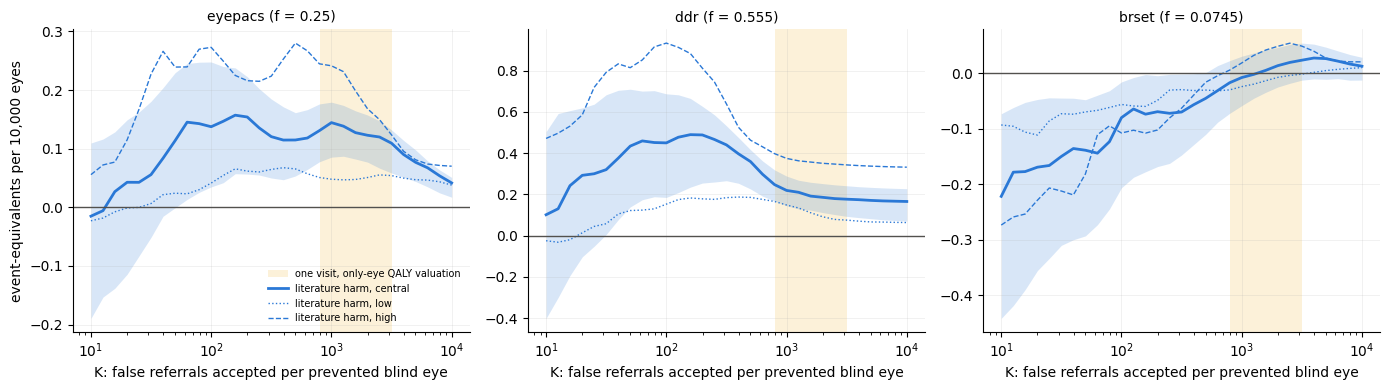

,population,harm,breakeven_K,ci_lo,ci_hi,point_value,share_resamples_not_ahead_at_top_of_grid
0,eyepacs,central,13,below 10,52,13.118505,0.000
1,eyepacs,low,25,below 10,116,25.287568,0.000
2,eyepacs,high,below 10,below 10,27,-inf,0.000
3,ddr,central,below 10,below 10,31,-inf,0.000
4,ddr,low,18,below 10,77,18.194093,0.000
5,ddr,high,below 10,below 10,17,-inf,0.000
6,brset,central,"1,332",531,"above 10,000",1331.929958,0.194
7,brset,low,"3,491","1,313","above 10,000",3491.177562,0.144
8,brset,high,694,286,"above 10,000",694.118852,0.086


eyepacs: pairing beats the better member once a programme accepts at least 13 false referrals per prevented blind eye (95% interval below 10 to 52)
ddr: the tuned pair is ahead across the whole grid, even at K = 10 (95% interval below 10 to 31)
brset: pairing beats the better member once a programme accepts at least 1,332 false referrals per prevented blind eye (95% interval 531 to above 10,000)


In [6]:
def breakeven(adv):
    # smallest K above which adv stays > 0 to the end of the grid, log-interpolated; -inf if positive everywhere, +inf if not positive at the top
    if adv[-1] <= 0: return np.inf
    neg = np.where(adv <= 0)[0]
    if len(neg) == 0: return -np.inf
    i = neg[-1]; a0, a1 = adv[i], adv[i + 1]; t = -a0 / (a1 - a0)
    return float(np.exp(np.log(KS[i]) + t * (np.log(KS[i + 1]) - np.log(KS[i]))))
def fmt(k): return f"below {KS[0]:.0f}" if k < KS[0] else (f"above {KS[-1]:,.0f}" if k > KS[-1] else f"{k:,.0f}")
def pct(bs, q): return float(np.percentile(np.clip(bs, KS[0] / 2, KS[-1] * 2), q))       # censored ends stay censored
fig, ax = plt.subplots(1, len(RES), figsize=(14, 4))
rows, be_rows = [], []
for x, (name, r) in zip(np.atleast_1d(ax), RES.items()):
    x.axvspan(800, 3200, color="#eda100", alpha=0.15, lw=0, label="one visit, only-eye QALY valuation")
    for sc, ls in (("central", "-"), ("low", ":"), ("high", "--")):
        tk = r["tuned_k"][sc]; pt = tk[0]; lo, hi = np.percentile(tk[1:], 2.5, 0), np.percentile(tk[1:], 97.5, 0)
        if sc == "central": x.fill_between(KS, lo, hi, color="#2a78d6", alpha=0.18, lw=0)
        x.plot(KS, pt, color="#2a78d6", lw=2 if sc == "central" else 1, ls=ls, label=f"literature harm, {sc}")
        for i, K in enumerate(KS): rows.append({"population": name, "harm": sc, "K": K, "advantage_event_equiv_per_10k": pt[i], "ci_lo": lo[i], "ci_hi": hi[i], "share_resamples_positive": float((tk[1:, i] > 0).mean())})
        bs = np.array([breakeven(tk[b]) for b in range(1, B + 1)])
        be_rows.append({"population": name, "harm": sc, "breakeven_K": fmt(breakeven(pt)), "ci_lo": fmt(pct(bs, 2.5)), "ci_hi": fmt(pct(bs, 97.5)), "point_value": breakeven(pt),
                        "share_resamples_not_ahead_at_top_of_grid": float((bs == np.inf).mean())})
    x.axhline(0, color="#52514e", lw=1); x.set_xscale("log"); x.set_title(f"{name} (f = {r['f']})", fontsize=10)
    x.set_xlabel("K: false referrals accepted per prevented blind eye"); x.grid(alpha=0.25, lw=0.5); [x.spines[s].set_visible(False) for s in ("top", "right")]
np.atleast_1d(ax)[0].set_ylabel("event-equivalents per 10,000 eyes"); np.atleast_1d(ax)[0].legend(fontsize=7, frameon=False)
fig.tight_layout(); fig.savefig(f"{FIGS}/litw_B_tuned_vs_K_v2.png", dpi=200); plt.show()
Bk = pd.DataFrame(rows); Bk.to_csv(f"{RESULTS}/litw_B_tuned_K_v2.csv", index=False)
BE = pd.DataFrame(be_rows); BE.to_csv(f"{RESULTS}/litw_B_breakeven_K_v2.csv", index=False); display(BE)
for _, b in BE[BE.harm == "central"].iterrows():
    k = b.point_value
    if k < KS[0]: msg = f"the tuned pair is ahead across the whole grid, even at K = {KS[0]:.0f}"
    elif k > KS[-1]: msg = f"the tuned pair is not ahead even at K = {KS[-1]:,.0f}"
    else: msg = f"pairing beats the better member once a programme accepts at least {b.breakeven_K} false referrals per prevented blind eye"
    print(f"{b.population}: {msg} (95% interval {b.ci_lo} to {b.ci_hi})")

## 5b. B2. The same in QALYs, only-eye valuation (secondary)
Tuned pair minus tuned better member, in QALYs per 10,000 eyes, across the false-positive price λ. Each arm chooses its own cheapest volume at each λ. Above zero means pairing is worth it once both sides are optimised. The shaded band is the assumed cost of one visit.

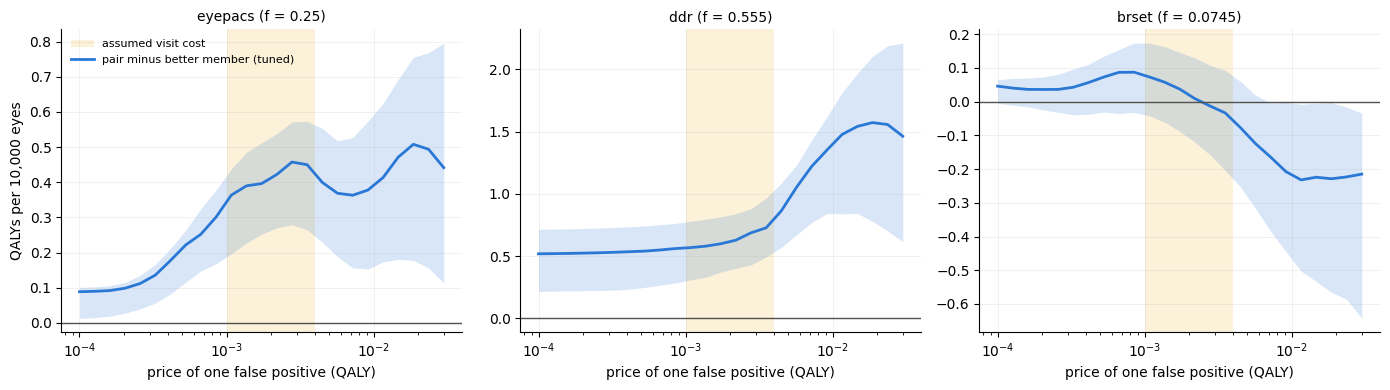

eyepacs: at lambda = 0.002786 QALY, tuned pair minus tuned better member = +0.457 QALYs per 10,000 (+0.279 to +0.571)
ddr: at lambda = 0.002786 QALY, tuned pair minus tuned better member = +0.687 QALYs per 10,000 (+0.429 to +0.881)
brset: at lambda = 0.002786 QALY, tuned pair minus tuned better member = -0.013 QALYs per 10,000 (-0.158 to +0.108)
eyepacs: the tuned pair stays ahead across the whole lambda grid (up to 0.03 QALY, i.e. down to 107 false referrals per event)
ddr: the tuned pair stays ahead across the whole lambda grid (up to 0.03 QALY, i.e. down to 107 false referrals per event)
brset: the tuned pair stops beating its better member near lambda = 0.002786 QALY, i.e. when one prevented event is valued below about 1152 false referrals


In [7]:
fig, ax = plt.subplots(1, len(RES), figsize=(14, 4), sharey=False)
rows = []
for x, (name, r) in zip(np.atleast_1d(ax), RES.items()):
    tq = r["tuned_qaly"]; pt = tq[0]; lo, hi = np.percentile(tq[1:], 2.5, 0), np.percentile(tq[1:], 97.5, 0)
    x.axvspan(*BAND, color="#eda100", alpha=0.15, lw=0, label="assumed visit cost")
    x.fill_between(LAMBDAS, lo, hi, color="#2a78d6", alpha=0.18, lw=0); x.plot(LAMBDAS, pt, color="#2a78d6", lw=2, label="pair minus better member (tuned)")
    x.axhline(0, color="#52514e", lw=1); x.set_xscale("log"); x.set_title(f"{name} (f = {r['f']})", fontsize=10); x.set_xlabel("price of one false positive (QALY)")
    x.grid(alpha=0.25, lw=0.5); [x.spines[s].set_visible(False) for s in ("top", "right")]
    for i, lam in enumerate(LAMBDAS): rows.append({"population": name, "lambda_qaly": lam, "advantage_qaly_per_10k": pt[i], "ci_lo": lo[i], "ci_hi": hi[i], "point_outside_ci": not (lo[i] <= pt[i] <= hi[i])})
np.atleast_1d(ax)[0].set_ylabel("QALYs per 10,000 eyes"); np.atleast_1d(ax)[0].legend(fontsize=8, frameon=False)
fig.tight_layout(); fig.savefig(f"{FIGS}/litw_B_tuned_vs_lambda_v2.png", dpi=200); plt.show()
Bt = pd.DataFrame(rows); Bt.to_csv(f"{RESULTS}/litw_B_tuned_lambda_v2.csv", index=False)
ia = int(np.argmin(np.abs(LAMBDAS - LAM_ANCHOR)))
for name, r in RES.items():
    p, lo, hi = ci(r["tuned_qaly"][:, ia]); print(f"{name}: at lambda = {LAMBDAS[ia]} QALY, tuned pair minus tuned better member = {p:+.3f} QALYs per 10,000 ({lo:+.3f} to {hi:+.3f})")
# break-even price (utility-free form): false referrals one prevented event is worth = QALY per event / lambda
QPE = SY["central"] * QALY_PER_BLIND_YEAR
for name, r in RES.items():
    pt = r["tuned_qaly"][0]; neg = np.where(pt <= 0)[0]
    if len(neg) == 0: print(f"{name}: the tuned pair stays ahead across the whole lambda grid (up to {LAMBDAS[-1]} QALY, i.e. down to {QPE / LAMBDAS[-1]:.0f} false referrals per event)")
    elif neg[0] == 0: print(f"{name}: the tuned pair is never ahead on the lambda grid")
    else:
        lam_be = LAMBDAS[neg[0]]; print(f"{name}: the tuned pair stops beating its better member near lambda = {lam_be} QALY, i.e. when one prevented event is valued below about {QPE / lam_be:.0f} false referrals")

## 6. C. The npj 25-cell weight grid, fully tuned (v2 data)
Each cell holds the mean advantage of the tuned pair over its tuned better member in npj index units per 10,000 eyes, with a 95% interval. This is the v2 replacement for the v1 invariance figure.

In [8]:
cells = [(a, b, c, wfp) for a, b, c in NPJ_GRID["miss"] for wfp in NPJ_GRID["wfp"]]
rows = []
for name, r in RES.items():
    for i, (a, b, c, wfp) in enumerate(cells):
        p, lo, hi = ci(r["tuned_grid"][:, i]); rows.append({"population": name, "miss_weights": f"{a}/{b}/{c}", "wfp": wfp, "advantage": p, "ci_lo": lo, "ci_hi": hi, "ci_excludes_zero_positive": lo > 0})
Cg = pd.DataFrame(rows); Cg.to_csv(f"{RESULTS}/litw_C_grid_tuned_v2.csv", index=False)
for name in RES:
    t = Cg[Cg.population == name]
    print(f"\n=== {name}: cells with the tuned pair ahead (point) {int((t.advantage > 0).sum())} of 25; with 95% interval above zero {int(t.ci_excludes_zero_positive.sum())} of 25 ===")
    display(t.pivot_table(index="miss_weights", columns="wfp", values="advantage", aggfunc="first").round(1))


=== eyepacs: cells with the tuned pair ahead (point) 25 of 25; with 95% interval above zero 24 of 25 ===


wfp,1,5,20,50,100
miss_weights,,,,,
100/50/10,350.1,620.6,603.6,628.3,414.4
1000/400/20,708.3,1888.6,3359.5,3234.6,3947.7
250/100/10,394.3,932.8,967.3,1259.9,1271.1
50/25/5,251.3,273.0,293.0,207.2,125.6
500/200/15,475.0,1469.4,1822.8,2021.1,2385.7



=== ddr: cells with the tuned pair ahead (point) 25 of 25; with 95% interval above zero 24 of 25 ===


wfp,1,5,20,50,100
miss_weights,,,,,
100/50/10,766.3,1133.5,1854.5,1544.2,1018.8
1000/400/20,3554.2,3775.9,4680.0,8454.8,10732.3
250/100/10,1174.8,1434.0,2977.4,3122.5,2960.2
50/25/5,396.6,840.6,805.8,509.4,338.8
500/200/15,2055.6,2235.7,3970.3,5814.9,5719.5



=== brset: cells with the tuned pair ahead (point) 7 of 25; with 95% interval above zero 1 of 25 ===


wfp,1,5,20,50,100
miss_weights,,,,,
100/50/10,91.1,-71.0,-57.3,-233.1,-257.7
1000/400/20,240.7,580.9,-140.9,-1155.4,-1450.4
250/100/10,157.1,-6.4,-366.5,-257.1,-672.0
50/25/5,17.0,-58.9,-120.2,-128.9,-144.7
500/200/15,137.5,196.6,-434.8,-707.2,-556.2


## 7. D. Union at each model's own threshold
Referring every eye either model flags at f, against the better member alone at f, per 10,000 eyes:
- harm avoided (QALYs);
- severe eyes avoided;
- extra false positives;
- net QALYs at the anchored λ, and at both ends of the band.

In [9]:
rows = []
for name, r in RES.items():
    hq, fp, sv = r["union_harm_qaly"], r["union_fp"], r["union_severe"]
    row = {"population": name, "f": r["f"]}
    for k, v in (("harm_avoided_qaly", hq), ("severe_eyes_avoided", sv), ("extra_false_positives", fp)):
        row[k], row[k + "_lo"], row[k + "_hi"] = ci(v)
    for lam in (BAND[0], LAM_ANCHOR, BAND[1]):
        row[f"net_qaly_at_{lam}"], row[f"net_qaly_at_{lam}_lo"], row[f"net_qaly_at_{lam}_hi"] = ci(hq - lam * fp)
    row["extra_fp_per_severe_avoided"] = float(fp[0] / sv[0]) if sv[0] > 0 else float("nan")
    ev = hq / (SY["central"] * QALY_PER_BLIND_YEAR)          # severe visual loss events avoided per 10,000 (utility-free)
    row["events_avoided"], row["events_avoided_lo"], row["events_avoided_hi"] = ci(ev)
    row["extra_fp_per_event_avoided"] = float(fp[0] / ev[0]) if ev[0] > 0 else float("nan")   # the union pays when K exceeds this
    for K in (100, 1000, 3200):
        row[f"net_events_at_K{K}"], row[f"net_events_at_K{K}_lo"], row[f"net_events_at_K{K}_hi"] = ci(ev - fp / K)
    rows.append(row)
D = pd.DataFrame(rows); D.to_csv(f"{RESULTS}/litw_D_union_v2.csv", index=False); display(D.round(3).T)

,0,1,2
population,eyepacs,ddr,brset
f,0.25,0.555,0.074
harm_avoided_qaly,1.24,2.876,1.56
harm_avoided_qaly_lo,1.014,1.811,1.204
harm_avoided_qaly_hi,1.462,4.022,1.889
severe_eyes_avoided,10.092,14.843,10.489
severe_eyes_avoided_lo,7.371,7.853,8.117
severe_eyes_avoided_hi,12.139,22.499,12.687
extra_false_positives,599.27,638.276,207.111
extra_false_positives_lo,579.219,522.897,196.386


## 8. Write the results record

In [10]:
def tolist(x): return {k: tolist(v) for k, v in x.items()} if isinstance(x, dict) else (x.tolist() if isinstance(x, np.ndarray) else x)
REC = {"status": "secondary, post hoc; not specified in a dated lock", "written_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(),
       "models": "33 EyePACS-trained v2 models, 55 pairs x 9 seed combinations", "bootstrap": {"resamples": B, "seed": SEED, "unit": "patients (EyePACS, BRSET), filename groups (DDR)", "conditional_on": "full-sample rank transforms"},
       "harm_model": {"pdr_svl_per_year": PDR, "g3": {"p_high_risk_within_year": P_HR_G3, "direct": DIRECT_G3}, "g2_p_pdr_within_year": P_PDR_G2,
                      "sight_years_per_event": SY, "qaly_per_blind_year": QALY_PER_BLIND_YEAR, "dme": "not modelled (unlabelled)", "valuation": "only-eye worst case: person-level blindness QALY loss charged to each single-eye event; upper bound on harm"},
       "false_positive_price": {"lambda_grid_qaly": LAMBDAS.tolist(), "assumed_band_qaly": BAND, "anchor_qaly": LAM_ANCHOR, "basis": "one visit $150 to $400 at $100,000 to $150,000 per QALY; to be sourced"},
       "populations": {n: {"eyes": r["n"], "groups": r["groups"], "f": r["f"]} for n, r in RES.items()},
       "primary_pricing": "K = false referrals per prevented severe visual loss event, swept 10 to 10,000",
       "A_matched_volume": A.to_dict("records"), "B_tuned_K": Bk.to_dict("records"), "B_breakeven_K": BE.to_dict("records"), "B2_tuned_lambda_only_eye": Bt.to_dict("records"), "C_grid_tuned": Cg.to_dict("records"), "D_union": D.to_dict("records"),
       "input_sha256": HASHES}
with open(OUT_JSON, "w") as fh: json.dump(tolist(REC), fh, indent=1, default=float)
print("written", OUT_JSON, "and four CSVs in 04_results; figure in 05_figures")

written /content/drive/MyDrive/stochastic_orthogonality/data/dr_ensemble_v2/04_results/literature_weighted_secondary_v2.json and four CSVs in 04_results; figure in 05_figures
